# Day 4(M1 Day04) 실습 — 병렬 분석과 통합·MCP 자료 연결

**목표**: 분석가 여럿에게 일을 동시에 나눠 보내고(fan-out) 결과를 한곳에 모은 뒤(fan-in), 통합자가 관점의 충돌을 **뭉개지 않고** 보고서로 합치게 한다. 자료는 MCP 서버에서 받아 팀에 넘긴다.
## 오늘의 전체 그림

**오늘의 질문**: 서로 기다릴 필요 없는 일을 왜 줄 세우나? 동시에 낸 결과는 충돌을 뭉개지 않고 어떻게 합치나?

```text
[Part 1 만든다]   Analysis 계약 · 관점 3종 PERSPECTIVES · dispatch(Send) fan-out · reducer(operator.add)
      │           → 동시 기록 충돌을 일부러 겪고 reducer로 푼다
      ▼
[Part 2 흔든다]   순차 vs 병렬 시간 · 통합자 aggregate(Report) · 관점 추가(딕셔너리 한 줄)
      │           → (확장) 통합 규칙이 없으면 충돌이 보고서에서 사라진다
      ▼
[Part 3 조립한다] fan-out + fan-in 그래프 research_team · 새 자료 재사용
                  → (확장) MCP 자료실 서버에서 자료를 받아 온다 (.py)
```

| Part | 블록 | 답하는 질문 | 다음 Part로 넘기는 것 |
| --- | --- | --- | --- |
| Part 1 | 따라 하기 | 분석가 여럿을 동시에 돌리면 무엇이 깨지나? | `analyze` · `dispatch` · `analyst_node` · `ResearchState` |
| Part 2 | 바꿔 보기 | 병렬은 얼마나 빠르고, 결과는 어떻게 합치나? | 통합자 `aggregate` · `Report`(conflicts) |
| Part 3 | 미니 프로젝트 | 나눠 보내기(fan-out)와 모아 합치기(fan-in)를 한 그래프로 | `research_team` · `run_parallel_research` → Day 5 품질 게이트 |

> 💡 세 Part는 코드를 이어 쓴다. 앞 Part의 셀을 실행하지 않으면 뒤 Part가 돌지 않는다.

> 💡 `Send` 병렬화·`operator.add` reducer·결과 합치기는 **2과목 Day 14 (2-5·2-6)** 에서 배웠다. 오늘 새로운 것은 **통합의 품질** — 관점이 부딪칠 때 그것을 숨기지 않고 남기는 법이다.

## 0. 환경 준비

> 💡 오늘도 흐름 제어는 LangGraph다. 새로 쓰는 것은 여럿에게 동시에 나눠 보내는 `Send`(fan-out)와, 동시 기록을 합치는 규칙인 reducer `operator.add`다. 한 노드로 다시 모으는 fan-in은 Part 3에서 통합자로 완성한다. Part 3-확장의 MCP 연결은 `langchain_mcp_adapters`로 하고, 노트북이 아니라 `.py`로 실행한다.

In [51]:
import os

# 추적 끄기: 2과목 Day17에서 .env의 LANGSMITH_TRACING을 켰다면 오늘 호출이 전부 전송된다
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"

import operator
import time
from typing import Annotated

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from langgraph.types import Send
from pydantic import BaseModel, Field
from typing_extensions import TypedDict

load_dotenv()

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.7)  # 분석가: 관점마다 다양하게
llm_strict = ChatOpenAI(model="gpt-4o-mini", temperature=0)  # 통합자: 흔들림 없이

SOURCE = """[내부 소개 자료] 달빛 도서관
달빛 도서관은 밤 10시부터 새벽 2시까지 여는 무인 야간 도서관이다.
서울 마포구에 1호점이 있으며, 좌석은 총 48석이다.
입장은 월 구독제이며, 구독료는 월 19,900원이다.
사서 대신 안내 로봇 '루나'가 책 추천과 반납을 돕는다.
조용한 환경을 위해 통화와 취식은 금지된다.
회원의 62%가 20~30대 직장인이다.
2026년 12월에 부산 2호점이 문을 열 예정이다."""

print("준비 완료:", llm.model_name)

준비 완료: gpt-4o-mini


## Part 1. 따라 하기 — 병렬 분석 (2과목 복습)

**전체 그림 1/3**: 관점별 분석가를 `Send`로 동시에 보내고, 동시 기록을 reducer로 합친다 → Part 2·3이 이 그래프 부품을 그대로 쓴다.

### 1-1. 분석 계약과 관점 3종

같은 자료를 서로 다른 관점에서 보는 분석가들이다. 서로의 결과가 필요 없다 → 동시에 돌려도 된다.

> 💡 관점 이름은 코드에서 고정한다. LLM에게 맡기면 실행마다 "낙관적인 성장 가능성", "이용자 입장에서의 분석"처럼 이름이 달라진다 (사전 검증에서 확인).

In [52]:
class Analysis(BaseModel):
    """분석가의 출력 계약"""

    points: list[str] = Field(description="이 관점에서 본 분석 포인트 3개. 각 포인트는 한 문장.")


PERSPECTIVES = {
    "optimist": ("낙관 분석가", "이 서비스의 강점과 성장 기회를 찾는다"),
    "pessimist": ("비관 분석가", "이 서비스의 약점과 사업 위험을 찾는다"),
    "customer": ("고객 분석가", "이용자 입장에서 좋은 점과 불편한 점을 찾는다"),
}


def analyze(key, source):
    """관점 key로 자료를 분석한다."""
    name, mission = PERSPECTIVES[key]
    prompt = f"당신은 {name}입니다. 임무: {mission}.\n다음 자료를 분석해 포인트 3개를 내세요.\n\n[자료]\n{source}"
    # TODO: llm에 Analysis 계약을 걸어 prompt를 호출하고 결과를 result에 담으세요
    result = llm.with_structured_output(Analysis).invoke(prompt)
    return {"perspective": name, "points": result.points}

In [53]:
sample = analyze("optimist", SOURCE)
print(f"[{sample['perspective']}]")
for p in sample["points"]:
    print("-", p)

[낙관 분석가]
- 야간 운영 시간: 밤 10시부터 새벽 2시까지 운영하는 무인 도서관으로, 직장인들의 야간 독서 공간을 제공하여 시간적 제약을 해소한다.
- 로봇 안내 서비스: '루나'라는 안내 로봇을 통해 독서 경험을 혁신적으로 개선하며, 기술적인 요소로 고객의 흥미를 유도하고 차별화된 서비스를 제공한다.
- 구독 모델: 월 구독제를 통해 지속적인 수익을 창출할 수 있으며, 특히 20~30대 직장인들을 주요 타겟층으로 설정하여 안정적인 고객층을 확보할 수 있는 기회가 있다.


### 1-2. 병렬 쓰기 충돌 — 일부러 겪어 보기

2과목에서 쓴 `Send`로 분석가 세 명을 동시에 보낸다. 이번에는 **reducer 없이** 같은 칸(`analyses`)에 쓰게 해 본다.

```text
        ┌→ analyst(낙관) ┐
START ──┼→ analyst(비관) ┼→ END
        └→ analyst(고객) ┘
```

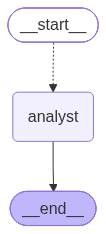

In [54]:
class BadState(TypedDict):
    source: str
    analyses: list[dict]  # reducer 없음 — 세 명이 같은 단계에 쓰면 충돌한다


def dispatch(state):
    """관점마다 analyst 노드를 하나씩 보낸다 (fan-out). 보낼 때 관점 key와 자료를 함께 넘긴다."""
    return [Send("analyst", {"key": k, "source": state["source"]}) for k in PERSPECTIVES]


def analyst_node(payload):
    """Send로 받은 key·source로 분석한다."""
    return {"analyses": [analyze(payload["key"], payload["source"])]}


g = StateGraph(BadState)
g.add_node("analyst", analyst_node)
g.add_conditional_edges(START, dispatch, ["analyst"])
g.add_edge("analyst", END)
bad_team = g.compile()
bad_team

In [55]:
try:
    bad_team.invoke({"source": SOURCE, "analyses": []})
    print("오류 없음 (예상 밖)")
except Exception as e:
    print("예외 발생:")
    print(e)

예외 발생:
At key 'analyses': Can receive only one value per step. Use an Annotated key to handle multiple values.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/INVALID_CONCURRENT_GRAPH_UPDATE


**관찰 포인트**: 오류 메시지를 끝까지 읽는다. 해결책이 메시지 안에 있는가?

> 💡 오류 없이 값을 덮어쓰는 것보다 예외를 내고 멈추는 것이 낫다 (Day 2 계약과 같은 원칙).

### 1-3. reducer 적용 — 동시 기록을 합치는 법 선언

`Annotated[list[dict], operator.add]` = "같은 단계에 여러 기록이 오면 리스트로 **이어 붙여라**"는 선언이다.

<details>
<summary>용어 미리 풀기 — reducer</summary>

- **reducer**: 여러 노드가 같은 칸에 쓴 값을 하나로 합치는 규칙이다.
- `operator.add`는 리스트 덧셈이다: `[a] + [b] + [c]` → `[a, b, c]`.
- 2과목 Day 14 2-5의 `results: Annotated[list, operator.add]`와 같다.
</details>

In [56]:
class ResearchState(TypedDict):
    source: str
    # TODO: analyses 칸을 만드세요 — 딕셔너리 리스트, 동시 기록을 이어 붙이는 reducer를 Annotated로 지정
    #       (힌트: operator 모듈의 리스트 덧셈)
    analyses: Annotated[list[dict], operator.add]
    report: dict


print("ResearchState 정의 완료 (reducer 적용)")

ResearchState 정의 완료 (reducer 적용)


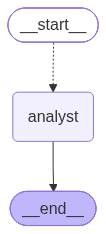

In [57]:
g = StateGraph(ResearchState)
g.add_node("analyst", analyst_node)
g.add_conditional_edges(START, dispatch, ["analyst"])
g.add_edge("analyst", END)
bad_team = g.compile()
bad_team

In [58]:
try:
    bad_team.invoke({"source": SOURCE, "analyses": []})
    print("오류 없음 (예상 밖)")
except Exception as e:
    print("예외 발생:")
    print(e)

오류 없음 (예상 밖)


### 1-4. fan-out 그래프 조립·실행

1-2와 같은 그래프에 State만 바꿨다.

In [59]:
g = StateGraph(ResearchState)
g.add_node("analyst", analyst_node)
# TODO: fan-out — START에서 dispatch로 분석가들을 보내는 조건 엣지와, 분석가가 END로 가는 엣지를 추가하세요
g.add_conditional_edges(START, dispatch, ["analyst"])
g.add_edge("analyst", END)
par_team = g.compile()

In [60]:
result = par_team.invoke({"source": SOURCE, "analyses": []})
print("수집된 분석:", len(result["analyses"]), "건")
for a in result["analyses"]:
    print(f"\n[{a['perspective']}]")
    for p in a["points"]:
        print("-", p)

수집된 분석: 3 건

[낙관 분석가]
- 야간 운영 시간: 밤 10시부터 새벽 2시까지 운영하여 직장인들이 퇴근 후 독서할 수 있는 시간을 제공, 이는 바쁜 일정을 가진 20~30대에게 큰 매력.
- 로봇 안내 시스템: '루나'라는 안내 로봇을 통해 고객 서비스의 혁신성을 강조, 인건비 절감과 함께 고객 경험 향상에 기여.
- 구독 모델: 월 19,900원의 저렴한 구독료를 통해 지속적인 수익 창출 가능, 이는 고객 충성도와 장기적인 이용 증가로 이어질 수 있음.

[비관 분석가]
- 무인 운영의 의존성: 안내 로봇 '루나'에 대한 의존도가 높아, 로봇의 고장이나 소프트웨어 문제 발생 시 서비스 제공에 큰 차질이 생길 수 있다. 고객의 불만과 이탈로 이어질 위험이 존재한다.
- 제한된 운영 시간: 야간 도서관으로서 운영 시간이 밤 10시부터 새벽 2시까지로 제한되어 있어, 수요가 많은 시간대에 고객을 충분히 수용하지 못할 수 있다. 이는 잠재 고객층을 놓치는 결과를 초래할 수 있다.
- 구독 기반 모델의 한계: 월 구독료 19,900원이 저렴하게 느껴질 수 있지만, 고객들이 지속적으로 구독을 유지할지에 대한 의문이 존재한다. 특히, 20~30대 직장인을 주 고객층으로 두고 있으나, 이들이 바쁜 생활 속에서 도서관을 자주 이용하지 않을 경우 구독 해지율이 높아질 수 있다.

[고객 분석가]
- 밤 늦은 시간에도 이용할 수 있는 무인 도서관으로, 직장인들에게 유용한 편의성을 제공한다.
- 입장 방식이 월 구독제로 단순하고, 비용이 상대적으로 저렴하여 지속적인 이용이 가능하다.
- 안내 로봇 '루나'를 통해 책 추천과 반납 서비스를 제공받아, 이용자의 편리함을 높이는 점이 긍정적이다.


## Part 2. 바꿔 보기 — 시간·통합·관점 추가

**전체 그림 2/3**: Part 1의 병렬 팀으로 시간을 재고, 분석 결과를 하나로 합치는 통합자를 만든다 → 통합자가 Part 3의 fan-in 노드가 된다.

### 2-1. 순차 vs 병렬 — 시간 실측

같은 분석 3건을 반복문(순차)과 그래프(병렬)로 실행해 시간을 비교한다.

> ⚠️ 이 셀은 LLM을 6번 호출한다. 네트워크 상태에 따라 수치가 요동치니 "경향"으로 읽는다.

In [61]:
start = time.time()
seq_results = []
# TODO: 세 관점(PERSPECTIVES)을 반복문으로 하나씩 analyze해 seq_results에 담으세요
for key in PERSPECTIVES:
    seq_results.append(analyze(key, SOURCE))
seq_time = time.time() - start

start = time.time()
# TODO: 병렬 그래프(par_team)를 원문(SOURCE)과 빈 analyses로 실행하고 결과를 result에 담으세요
result = par_team.invoke({
    "source": SOURCE,
    "analyses": [],
})
par_time = time.time() - start

print(f"순차 3건: {seq_time:.1f}초 (시간의 합)")
print(f"병렬 3건: {par_time:.1f}초 (가장 느린 한 명)")

순차 3건: 5.9초 (시간의 합)
병렬 3건: 2.1초 (가장 느린 한 명)


In [62]:
PERSPECTIVES["finance"] = ("재무 분석가", "수익 구조와 비용 관점에서 지속 가능성을 분석한다")

In [63]:
start = time.time()
seq_results = []
# TODO: 세 관점(PERSPECTIVES)을 반복문으로 하나씩 analyze해 seq_results에 담으세요
for key in PERSPECTIVES:
    seq_results.append(analyze(key, SOURCE))
seq_time = time.time() - start

start = time.time()
# TODO: 병렬 그래프(par_team)를 원문(SOURCE)과 빈 analyses로 실행하고 결과를 result에 담으세요
result = par_team.invoke({
    "source": SOURCE,
    "analyses": [],
})
par_time = time.time() - start

print(f"순차 4건: {seq_time:.1f}초 (시간의 합)")
print(f"병렬 4건: {par_time:.1f}초 (가장 느린 한 명)")

순차 4건: 11.2초 (시간의 합)
병렬 4건: 3.4초 (가장 느린 한 명)


**관찰 포인트**: 순차는 합, 병렬은 가장 느린 한 명의 시간에 가까운가? 분석가가 많아지면 격차는 어떻게 될까?

### 2-2. 통합자(Aggregator) — 모으기를 넘어 합치기로

reducer는 **모으기만** 한다 (기계적). 요약·대조·결론은 판단이 필요하다 → 통합자 에이전트가 맡는다.

통합 원칙: **다수결로 뭉개지 않고, 충돌은 `conflicts`에 남긴다.**

In [65]:
class Report(BaseModel):
    """통합 보고서 계약"""

    title: str = Field(description="통합 보고서 제목")
    summary: str = Field(description="모든 관점을 종합한 요약 (3~4문장)")
    # TODO: conflicts 필드를 만드세요 — 문자열 리스트, description은 "관점이 서로 충돌하는 지점 (없으면 빈 리스트)"
    conflicts: list[str] = Field(description="관점이 서로 충돌하는 지점 (없으면 빈 리스트)")
    recommendation: str = Field(description="종합 판단 한 줄")


def analyses_to_text(analyses):
    """분석 목록을 통합자에게 줄 글로 바꾼다."""
    lines = []
    for a in analyses:
        lines.append(f"[{a['perspective']}]")
        for p in a["points"]:
            lines.append(f"- {p}")
        lines.append("")
    return "\n".join(lines)


AGG_RULES = """- 각 관점을 공정하게 반영한다. 다수결로 뭉개지 않는다.
- 관점이 충돌하는 지점은 숨기지 말고 conflicts에 명시한다.
- 모든 내용은 한국어로 쓴다."""


def aggregate(analyses, rules=AGG_RULES):
    """통합자(Aggregator): 여러 분석을 하나의 보고서로 합친다."""
    prompt = f"당신은 통합자(Aggregator)입니다. 분석가들의 결과를 하나의 보고서로 합치세요.\n{rules}\n\n{analyses_to_text(analyses)}"
    return llm_strict.with_structured_output(Report).invoke(prompt)

In [66]:
PERSPECTIVES

{'optimist': ('낙관 분석가', '이 서비스의 강점과 성장 기회를 찾는다'),
 'pessimist': ('비관 분석가', '이 서비스의 약점과 사업 위험을 찾는다'),
 'customer': ('고객 분석가', '이용자 입장에서 좋은 점과 불편한 점을 찾는다'),
 'finance': ('재무 분석가', '수익 구조와 비용 관점에서 지속 가능성을 분석한다')}

In [67]:
report = aggregate(result["analyses"])
print("[제목]", report.title)
print("[요약]", report.summary)
print("[충돌 지점]")
for c in report.conflicts:
    print("-", c)
print("[종합 판단]", report.recommendation)

[제목] 달빛 도서관 운영 분석 보고서
[요약] 본 보고서는 달빛 도서관의 운영 모델에 대한 다양한 분석가들의 의견을 종합하여 작성되었습니다. 낙관 분석가는 야간 운영과 기술 기반 서비스의 장점을 강조하며, 부산 2호점 개설 계획을 통해 사업 확장을 기대하고 있습니다. 반면 비관 분석가는 무인 운영의 한계와 특정 연령대에 집중된 고객층의 문제를 지적하며, 야간 운영의 안전 문제를 우려하고 있습니다. 고객 분석가는 야간 운영의 편리함과 구독제의 장점을 언급하면서도, 기술에 대한 불편함을 지적하고 있습니다. 재무 분석가는 구독 모델의 안정성과 비용 구조의 효율성을 강조하며, 초기 회원 모집의 중요성을 언급하고 있습니다.
[충돌 지점]
- 무인 운영의 장점과 단점: 낙관 분석가는 로봇 '루나'의 혁신성을 강조하지만, 비관 분석가는 기술적 오류로 인한 불편함을 우려하고 있다.
- 야간 운영의 장점과 위험: 낙관 분석가는 야간 운영의 매력을 강조하는 반면, 비관 분석가는 범죄 및 사고의 위험성을 지적하고 있다.
- 특정 연령대 집중 문제: 비관 분석가는 20~30대 직장인에 집중된 고객층이 성장 가능성을 제한한다고 주장하지만, 재무 분석가는 이 연령대의 독서 수요가 높다고 평가하고 있다.
[종합 판단] 달빛 도서관은 야간 운영의 장점을 살리면서도 안전 문제를 해결하기 위한 방안을 마련해야 합니다. 또한, 다양한 연령대와 계층의 고객을 유치하기 위한 마케팅 전략을 수립하고, 기술에 익숙하지 않은 이용자들을 위한 교육 프로그램이나 지원 시스템을 도입하는 것이 필요합니다. 초기 회원 모집을 위한 프로모션과 함께, 로봇 유지 관리 비용을 고려한 효율적인 운영 방안을 마련해야 합니다.


**관찰 포인트**: `conflicts`에 어떤 대립이 남았는가? 비어 있다면 → 관점 설계가 비슷비슷하거나, 통합자가 대립을 뭉갠 것이다. 둘 다 점검 대상이다.

### 2-3. 관점 추가 — 딕셔너리 한 줄

재무 분석가를 추가한다. `dispatch`가 `PERSPECTIVES`를 돌며 보내므로 **그래프는 다시 만들 필요가 없다**.

In [68]:
# TODO: PERSPECTIVES에 "finance" 관점을 추가하세요 (이름: "재무 분석가", 임무: 수익 구조와 비용 관점 분석)

start = time.time()
result4 = par_team.invoke({"source": SOURCE, "analyses": []})
print(f"분석가 {len(result4['analyses'])}명 병렬: {time.time() - start:.1f}초")
for a in result4["analyses"]:
    print(f"- [{a['perspective']}] {a['points'][0]}")

분석가 4명 병렬: 2.7초
- [낙관 분석가] 야간 운영으로 독서를 원하는 직장인들에게 최적의 환경 제공: 달빛 도서관은 밤 10시부터 새벽 2시까지 운영되므로, 일과 후 여유 시간에 독서를 즐기고자 하는 직장인들에게 매우 매력적이다. 이러한 시간대는 기존 도서관에서는 제공하지 않는 서비스로, 사용자들이 집중할 수 있는 조용한 환경을 제공하여 높은 이용률을 기록할 것으로 기대된다.
- [비관 분석가] 무인 운영의 한계: '루나' 로봇으로 운영되는 도서관은 인적 서비스가 부족하여 이용자의 다양한 요구를 충족시키기 어려울 수 있다. 특히, 기술적 오류나 고장이 발생할 경우 즉각적인 대처가 불가능할 수 있다.
- [고객 분석가] 야간 운영: 밤 10시부터 새벽 2시까지 운영되어, 직장인들이 퇴근 후 이용하기에 적합하다.
- [재무 분석가] 구독 기반 모델: 월 구독료 19,900원으로 안정적인 수익을 창출하며, 48석의 좌석을 고려할 때 한 달 최대 1,200명의 회원을 수용할 수 있어 연간 약 2억 3천만원의 수익을 예상할 수 있다.


**관찰 포인트**: 분석가가 4명이 되었는데 시간은 3명일 때(2-1)와 비교해 어떤가? 그래프 코드를 한 줄이라도 고쳤는가?

## Part 2-확장. 통합 규칙 실험 — 규칙이 없으면 충돌이 사라진다

통합자 프롬프트의 규칙 세 줄이 정말 일을 하는지 확인한다. 같은 분석 결과를 **규칙 있는 통합자**와 **규칙 없는 통합자**에게 각각 3번씩 넘기고, 남긴 충돌 개수를 센다.

> ⚠️ 이 셀은 LLM을 6번 호출한다.

In [69]:
analyses = result4["analyses"]  # 2-3의 분석 4건을 그대로 쓴다

In [70]:
analyses

[{'perspective': '낙관 분석가',
  'points': ['야간 운영으로 독서를 원하는 직장인들에게 최적의 환경 제공: 달빛 도서관은 밤 10시부터 새벽 2시까지 운영되므로, 일과 후 여유 시간에 독서를 즐기고자 하는 직장인들에게 매우 매력적이다. 이러한 시간대는 기존 도서관에서는 제공하지 않는 서비스로, 사용자들이 집중할 수 있는 조용한 환경을 제공하여 높은 이용률을 기록할 것으로 기대된다.',
   "로봇 안내 시스템으로 효율적인 서비스 제공: 사서 대신 안내 로봇 '루나'가 책 추천과 반납을 도와줌으로써, 고객들은 더욱 빠르고 효율적인 서비스를 받을 수 있다. 이는 운영 비용 절감으로 이어질 수 있으며, 고객들에게는 혁신적이고 현대적인 경험을 제공할 수 있다.",
   '부산 2호점 개설을 통한 시장 확장 가능성: 2026년 12월 부산 2호점 개설 예정은 달빛 도서관의 성공적인 시장 확장을 의미한다. 새로운 지역에 진출함으로써 더 많은 고객층을 확보할 수 있으며, 특히 대도시에서의 반응이 긍정적일 경우 추가 지점 개설의 기회도 열릴 수 있다.']},
 {'perspective': '비관 분석가',
  'points': ["무인 운영의 한계: '루나' 로봇으로 운영되는 도서관은 인적 서비스가 부족하여 이용자의 다양한 요구를 충족시키기 어려울 수 있다. 특히, 기술적 오류나 고장이 발생할 경우 즉각적인 대처가 불가능할 수 있다.",
   '제한된 이용 시간: 밤 10시부터 새벽 2시까지 운영되는 시간은 많은 사람들에게 불편함을 초래할 수 있다. 특히, 출퇴근 시간이 맞지 않는 직장인이나 야간 근무를 하는 이용자들에게는 접근성이 떨어진다.',
   '구독 모델의 리스크: 월 구독제로 운영되기 때문에 일정 수의 구독자를 유지해야 한다. 그러나 경제적 불황이나 경쟁 서비스의 등장으로 구독자 수가 감소할 경우 수익성에 큰 영향을 미칠 수 있다.']},
 {'perspective': '고객 분석가',
  'points': ['야간 운영: 밤 10시부터

In [72]:
with_rules = []
without_rules = []
for i in range(3):
    with_rules.append(len(aggregate(analyses).conflicts))
    without_rules.append(len(aggregate(analyses, rules="").conflicts))  # 규칙 세 줄을 빼고 통합

print("규칙 있음 — 충돌 개수:", with_rules)
print("규칙 없음 — 충돌 개수:", without_rules)

규칙 있음 — 충돌 개수: [3, 3, 3]
규칙 없음 — 충돌 개수: [3, 3, 3]


**관찰 포인트**: 규칙이 없을 때 충돌 개수가 줄었는가? 계약(`conflicts` 칸)만으로도 충돌이 남는다면, 규칙 세 줄의 역할은 무엇일까?

## Part 3. 미니 프로젝트 — 병렬 조사 → 통합 보고서 생성기

**전체 그림 3/3**: Part 1의 fan-out과 Part 2의 통합자를 한 그래프로 잇는다 → 확장에서 자료를 팀 밖(MCP 서버)에서 받아 온다.

분석가에게 나눠 보내기(fan-out) + 통합자로 모으기(fan-in)를 그래프 하나로 완성한다.

```text
        ┌→ analyst(낙관) ┐
자료 ───┼→ analyst(비관) ┼→ aggregator → 보고서
        ├→ analyst(고객) ┤
        └→ analyst(재무) ┘
```

### 3-1. 전체 그래프 조립 — fan-out + fan-in

모든 분석가가 `aggregator`로 모인다. aggregator는 **분석가가 모두 끝난 뒤 한 번만** 실행된다.

In [73]:
def aggregator_node(state):
    # TODO: state에 모인 분석들(analyses)을 aggregate에 넘겨 결과를 r에 담으세요
    r = aggregate(state["analyses"])
    return {"report": r.model_dump()}  # 계약 객체를 딕셔너리로 바꿔 State에 담는다


g = StateGraph(ResearchState)
g.add_node("analyst", analyst_node)
g.add_node("aggregator", aggregator_node)
g.add_conditional_edges(START, dispatch, ["analyst"])  # fan-out
# TODO: fan-in — 분석가들이 어디로 모여야 할까요? 엣지를 추가하세요
g.add_edge(["analyst"], "aggregator")
g.add_edge("aggregator", END)
research_team = g.compile()

print("병렬 조사 팀 조립 완료")

병렬 조사 팀 조립 완료


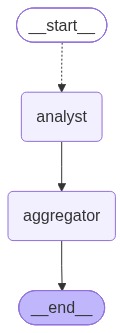

In [74]:
research_team

### 3-2. 실행 — 보고서 생성기

In [75]:
def run_parallel_research(source):
    """병렬 조사 → 통합 보고서 생성기"""
    start = time.time()
    result = research_team.invoke({"source": source, "analyses": []})
    report = result["report"]
    print(f"(분석 {len(result['analyses'])}건 → 보고서 1건, {time.time() - start:.1f}초)")
    print("[제목]", report["title"])
    print("[요약]", report["summary"])
    print("[충돌 지점]")
    for c in report["conflicts"]:
        print("-", c)
    print("[종합 판단]", report["recommendation"])
    return report


report = run_parallel_research(SOURCE)

(분석 4건 → 보고서 1건, 6.4초)
[제목] 달빛 도서관 운영 분석 보고서
[요약] 본 보고서는 달빛 도서관의 운영 방안에 대한 다양한 분석가들의 의견을 종합하여 작성되었습니다. 낙관 분석가는 야간 운영과 로봇 서비스를 통한 혁신적인 접근을 강조하며, 비관 분석가는 운영 시간과 무인 시스템의 의존성으로 인한 한계를 지적합니다. 고객 분석가는 야간 이용의 장점과 조용한 환경을 강조하고, 재무 분석가는 수익 구조와 비용 절감 요소를 분석합니다. 각 관점의 충돌 지점도 명시하여 균형 잡힌 시각을 제공합니다.
[충돌 지점]
- 야간 운영 시간의 유용성에 대한 의견 차이: 낙관 분석가는 직장인 수요를 충족한다고 보지만, 비관 분석가는 대다수 이용자에게 불리하다고 주장.
- 무인 시스템의 의존성 문제: 낙관 분석가는 로봇 서비스의 혁신성을 강조하지만, 비관 분석가는 기술적 문제 발생 시 고객 서비스에 차질이 생길 수 있다고 경고.
- 구독 모델의 한계: 비관 분석가는 일회성 방문객을 고려하지 않아 고객 유입에 제한을 줄 수 있다고 지적하는 반면, 재무 분석가는 지속적인 수익 구조를 긍정적으로 평가한다.
[종합 판단] 달빛 도서관은 야간 운영의 장점을 살리면서도 다양한 고객층을 유치하기 위해 운영 시간을 조정할 필요가 있습니다. 또한, 로봇 서비스의 의존성을 줄이기 위해 인력 지원 시스템을 마련하고, 구독 모델 외에도 일회성 이용객을 위한 유연한 요금제를 도입하는 것이 바람직합니다. 이를 통해 고객 만족도를 높이고, 지속 가능한 수익 구조를 확보할 수 있을 것입니다.


### 3-3. 새 자료로 재사용

In [76]:
SOURCE2 = """[내부 소개 자료] 새벽 수영 클럽
새벽 수영 클럽은 평일 오전 5시 30분부터 7시까지 운영하는 직장인 수영 모임이다.
장소는 성수동의 실내 수영장이며, 레인 3개를 통째로 빌려 쓴다.
월 회비는 89,000원이고, 강습료가 포함되어 있다.
초급반·중급반·자유수영반 세 반으로 나뉜다.
수료 기준을 통과하면 한강 야외 수영 행사에 참가할 수 있다.
현재 회원은 74명이며 대기자가 30명이 넘는다."""

report2 = run_parallel_research(SOURCE2)

(분석 4건 → 보고서 1건, 6.0초)
[제목] 새벽 수영 클럽 운영 분석 보고서
[요약] 본 보고서는 새벽 수영 클럽의 운영 현황에 대한 다양한 분석가들의 의견을 종합하여 작성되었습니다. 낙관 분석가는 클럽의 교육 프로그램과 회원 간의 유대감을 강조하며 긍정적인 전망을 제시하였고, 비관 분석가는 운영 시간과 시설의 한정성으로 인한 문제점을 지적하였습니다. 고객 분석가는 이른 시간대 운영의 장점과 강습 포함의 혜택을 강조하였으며, 재무 분석가는 안정적인 수익 구조와 회원 모집의 잠재력을 언급하였습니다. 각 관점이 공정하게 반영되었으며, 충돌하는 지점도 명시하였습니다.
[충돌 지점]
- 운영 시간의 제약: 낙관 분석가는 이른 시간대 운영이 직장인들에게 유리하다고 보았으나, 비관 분석가는 일부 직장인들이 참여하기 어려운 점을 지적하였다.
- 시설의 한정성: 비관 분석가는 레인 수의 제한으로 인해 수업 참여 인원이 제한된다고 언급했으나, 낙관 분석가는 대기자 수 증가가 추가 반 개설의 기회로 작용할 수 있다고 주장하였다.
- 회원 관리의 복잡성: 비관 분석가는 대기자들에게 불만을 초래할 수 있다고 경고했으나, 고객 분석가는 수료 기준이 목표를 부여한다고 긍정적으로 평가하였다.
[종합 판단] 운영 시간을 조정하여 더 많은 직장인이 참여할 수 있도록 하고, 시설 확장을 고려하여 수업 참여 인원을 늘리는 방안을 모색해야 합니다. 또한, 대기자 관리 방안을 마련하여 회원들의 불만을 최소화하고, 수료 기준을 재검토하여 대기자들에게도 참여 기회를 제공하는 방향으로 개선할 필요가 있습니다.


**관찰 포인트**: 자료가 바뀌어도 코드를 고치지 않았다. 보고서의 충돌 지점은 자료에 맞게 달라졌는가?

## Part 3-확장. MCP 자료실 — 자료를 팀 밖에서 받아 오기

지금까지 자료(`SOURCE`)는 노트북 안에 적혀 있었다. 실제 서비스에서는 자료가 **다른 시스템**(자료실·DB·검색)에 있다.
2과목 Day 7의 **MCP**로 자료실 서버를 만들고, 분석 팀이 그 서버에서 자료를 받아 오게 한다.

| 컨텍스트 전달 방법 | 범위 | 배운 곳 |
| --- | --- | --- |
| State (TypedDict) | 한 그래프 안의 노드끼리 | 2과목 Day 14 · 3과목 Day 3~4 |
| 인계서 (Pydantic) | 역할끼리, 빠짐없이 | 3과목 Day 2 |
| **MCP** | **다른 프로그램(서버)과**, 표준 규격으로 | 2과목 Day 7 · 오늘 |

> ⚠️ Windows·Jupyter에서는 MCP stdio 연결이 막힌다 → 2과목 Day 7처럼 **`.py` 스크립트**로 실행한다.

### 3-4. 파일 두 개

| 파일 | 역할 |
| --- | --- |
| `source_server.py` | 자료실 MCP 서버 — 도구 `list_sources()`, `get_source(name)` |
| `Day04-MCP자료실연결-실습.py` | 클라이언트 — 서버에 연결해 자료를 받고 분석가 3명에게 넘긴다 |

서버 파일은 완성되어 있다. 클라이언트의 `# TODO` 3곳을 채운다 (transport 이름, 도구 이름 2개).

### 3-5. 실행

`source_server.py`·`Day04-MCP자료실연결-실습.py`가 있는 폴더(이 노트북과 같은 폴더)에서 터미널로 실행한다.

```powershell
uv run python Day04-MCP자료실연결-실습.py
```

실행 결과를 아래에 붙여 넣는다.

```text
(여기에 붙여 넣기)
```

**관찰 포인트**

- 없는 자료를 요청했을 때 서버는 오류를 냈는가, 안내 문구를 돌려줬는가?
- `analyze()` 함수를 고쳤는가? 분석가는 자료가 어디서 왔는지 알아야 하는가?

### 3-6. 미션 — MCP 자료실을 그래프에 연결하기

위 스크립트는 자료를 MCP에서 받지만, 분석가는 `for` 반복문으로 **차례로** 부른다. 그래프도 통합자도 없다.
이번 미션은 자료 받기를 그래프의 **첫 노드**로 넣어 Part 3의 `research_team`과 잇는다.

```text
START → fetch → analyst × 3 → aggregator → END
```

| TODO | 할 일 |
| --- | --- |
| 1 | `fetch_node`: `get_source` 도구로 원문을 받아 `source` 칸에 담는다 |
| 2 | fan-out: `fetch` 뒤에 `dispatch`로 분석가를 보내는 조건 엣지 |
| 3 | fan-in: 분석가가 통합자로 모이는 엣지 |
| 4 | 실행: 자료 이름만 넘겨 `ainvoke` |

> 💡 그래프 안에서 MCP 도구를 부르므로 `fetch_node`는 `async def`이고, 그래프는 `invoke`가 아니라 `ainvoke`로 실행한다.

> ⚠️ LLM을 4번 호출한다 (분석 3 + 통합 1).

미션 파일은 `Day04-MCP자료실연결-그래프-실습.py`다. 3-5와 같은 폴더에서 실행한다.

```powershell
uv run python Day04-MCP자료실연결-그래프-실습.py
```

실행 결과를 아래에 붙여 넣는다.

```text
(여기에 붙여 넣기)
```

**관찰 포인트**

- 입력에 `source`를 넣지 않았다. 분석가는 원문을 어디서 받았나?
- `analyze()`와 `aggregate()`를 노트북에서 고쳐 왔는가?
- 반복문 버전에는 없던 것이 결과에 무엇이 생겼나?

## 확인 문제

1. 병렬 노드가 reducer 없는 칸에 동시에 쓰면 어떻게 되는가? 오류 메시지는 무엇을 안내했나?
2. `operator.add` reducer는 병렬 기록을 어떻게 처리하는가?
3. 순차와 병렬의 시간은 각각 무엇에 가까운가?
4. reducer와 통합자(Aggregator)는 무엇이 다른가?
5. 통합자가 다수결을 쓰지 않고 충돌을 `conflicts`에 남기는 이유는?
6. MCP로 자료를 받으면 무엇이 좋아지는가?

## 정리·회고

**M1 지도 — 지금까지 리서치 팀에 붙은 것**

| Day | 배운 것 | 팀에 추가된 것 |
| --- | --- | --- |
| 1 | 구조가 품질을 올린다, 판정은 코드로 | 작성자·검사기·수정자 |
| 2 | 역할 정의서·데이터 계약·업무 인계 | 조사원·작성자·검토자 + 계약 + 인계서 |
| 3 | Supervisor·Router 분배 | 관리자, 상담 봇 |
| 4 | 병렬 fan-out/fan-in·통합·MCP | 분석가 4명 + 통합자 + 자료실 서버 |

오늘 배운 것을 3줄로 정리해 본다.

1. 병렬로 돌릴 수 있는 일의 조건은?
2. 통합자가 지켜야 할 원칙과, 그 원칙이 실제로 일을 했는지 확인한 방법은?
3. State·인계서·MCP는 각각 어디서 어디로 컨텍스트를 넘기는가?

```powershell
git add .
git commit -m "Day4: 병렬 분석 + 통합 보고서 + MCP 자료실"
```

**내일 예고 (Day 5, M1 마지막)**: 통합 보고서의 품질은 누가 보장하나? 검증자(Evaluator)의 점수 기반 **피드백 루프**와 재시도 전략으로 M1 리서치 팀을 완성한다.